# 3. Draw maps

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Khoshkhah/duckOSM/blob/main/docs/notebooks/03_maps.ipynb) <a href="https://khoshkhah.github.io/duckOSM/notebooks/03_maps.ipynb" download><img src="https://img.shields.io/badge/Download-notebook-F37626?logo=jupyter&logoColor=white" alt="Download the notebook"></a>

<img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/banner-3.svg" alt="duckOSM notebook manual, chapter 3: Draw maps" width="100%">

| **You learn** | the live map and the static picture, the colors of the modes, how a notebook shows a map (`show=`), the map of one mode, the base map (`layers=`), the themes, color by a column, highlight edges, the dashboard, a map as an HTML file, web maps with folium and lonboard, a picture for a paper |
|---|---|
| **Time** | about 2 minutes |
| **Extras** | `duckosm[viz]` (the install cell installs them) |
| **Next** | [4. Join your data by edge_id](04_join_by_edge_id.md): your own data on the edges, and on the map |

In [1]:
# Install duckOSM when it is not installed (for example in Colab). It takes approximately 1 minute.
# Until duckOSM 0.9.0 is on PyPI, the SDK of these notebooks is in the nightly wheel of main (the GitHub pre-release "nightly").
import importlib.util, json, os, urllib.request
def nightly_wheel():       # the address of the newest nightly wheel
    release = json.load(urllib.request.urlopen("https://api.github.com/repos/Khoshkhah/duckOSM/releases/tags/nightly"))
    return next(a["browser_download_url"] for a in release["assets"] if a["name"].endswith(".whl"))
if importlib.util.find_spec("duckosm") is None:      # not installed: install it with the extras of this notebook
    %pip install -q "duckosm[viz] @ {nightly_wheel()}"
    %pip install -q folium mapclassify lonboard
import duckosm             # the SDK
if not hasattr(duckosm, "network"):                    # an old duckOSM (0.8.0 or older), without the SDK
    %pip install -q --force-reinstall --no-deps "duckosm @ {nightly_wheel()}"
    raise SystemExit("duckOSM is updated: restart the session (in Colab: Runtime > Restart session), then run this cell again")
print("duckosm", duckosm.__version__)    # the version
# The network of chapter 1 (monaco.duckdb). The chapter opens it. When you run this chapter alone (in Colab), the file
# is not there, so this cell makes it one time.
if not os.path.exists("monaco.duckdb") or not duckosm.open("monaco.duckdb").has_mode("driving", "walking", "cycling"):
    duckosm.network(osm_id=2220322, modes=["driving", "walking", "cycling"], path="monaco.duckdb")

duckosm 0.8.0


## Two kinds of map

duckOSM draws a network in two ways.

| | The live map | The static picture |
|---|---|---|
| Made by | [roadstyle](https://github.com/Khoshkhah/roadstyle), in the browser (MapLibre) | matplotlib, in Python |
| Calls | `net.map()`, `net.dashboard()`, `net.save_map()` | `net.plot()`, or `show="plot"` |
| You can | zoom, pan, click a road to see its columns, turn the layers on and off | save it as PNG or PDF, put it in a paper, draw it on your own axes |
| Draws | the roads with their casing (the dark border line), bridges over tunnels, the base map of the file, the labels | the roads as lines, and five layers of the base map |
| Size in the notebook (Monaco) | about 6 MB | a small PNG |

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-key.svg" width="18" height="18" alt=""> **Key idea**
>
> The same call gives a live map or a picture. `net.map()` gives the live map in a notebook. With `show="plot"`, it gives the static picture, with the same options. So you write the map one time and choose later how to show it.

## Open the network of chapter 1

Chapter 1 builds Monaco with three modes (driving, walking and cycling) and saves it as `monaco.duckdb`. This
chapter opens that file with `duckosm.open`. It builds nothing.

In [2]:
net = duckosm.open("monaco.duckdb")    # the network of chapter 1: Monaco, three modes
net

Network('monaco.duckdb', 37.0 MB, driving 2840 edges, walking 11938 edges, cycling 11305 edges)

## The live map: `net.map()`

`net.map()` with no mode draws all the roads of the file with roadstyle, over the base map of the file. In your
notebook, it is a live map: zoom, pan, and click a road to see its columns (its `edge_id`, its name, its road class
and its modes). The outputs of this page are pictures of the live maps (section "How the notebook shows a map").

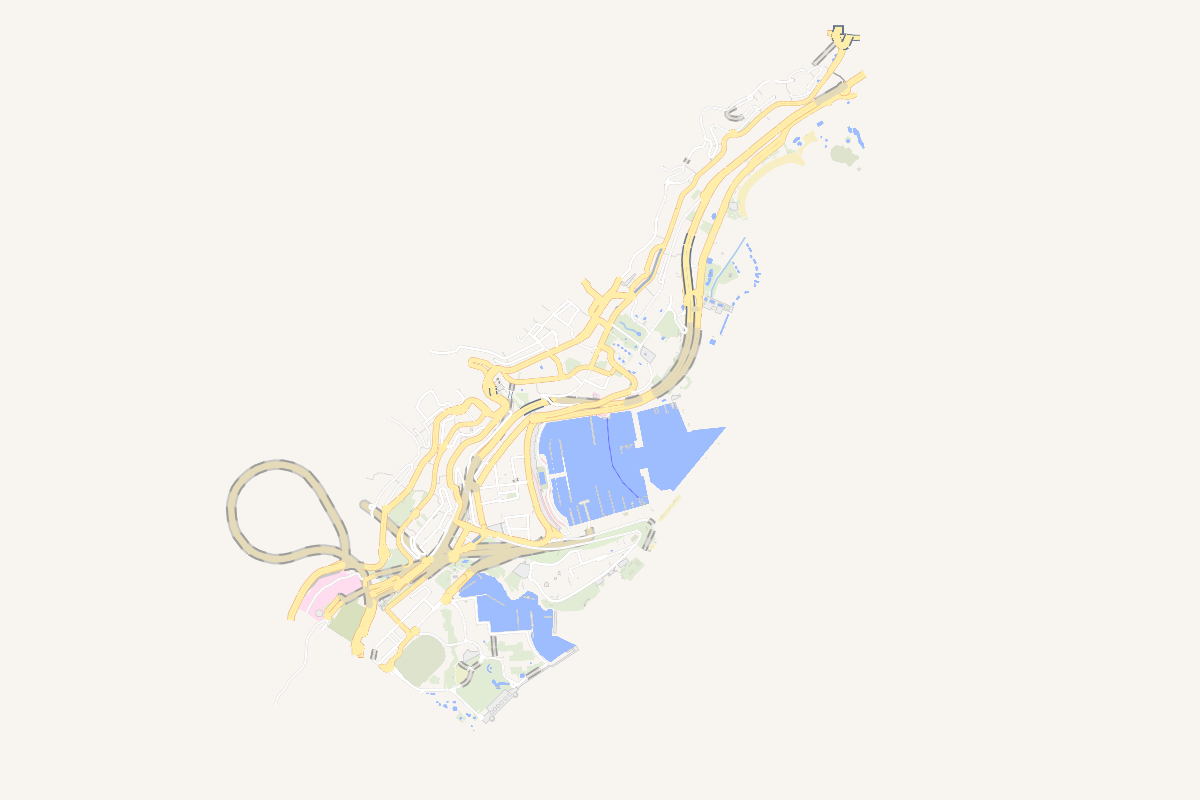

In [3]:
net.map()          # the live map of all modes (this page: a picture of it)

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The main roads are yellow, and the small streets and the footways are white. The tunnels are dashed, for example the loop in the west. The harbors are blue, and the parks are green. Bridges are drawn over the roads under them.

## The static picture: `net.plot()`

`net.plot()` draws the same roads with matplotlib. A road can be in one, two or three modes (chapter 2, "The same edge
in each mode"). The picture draws each road one time, with the color of its set of modes.

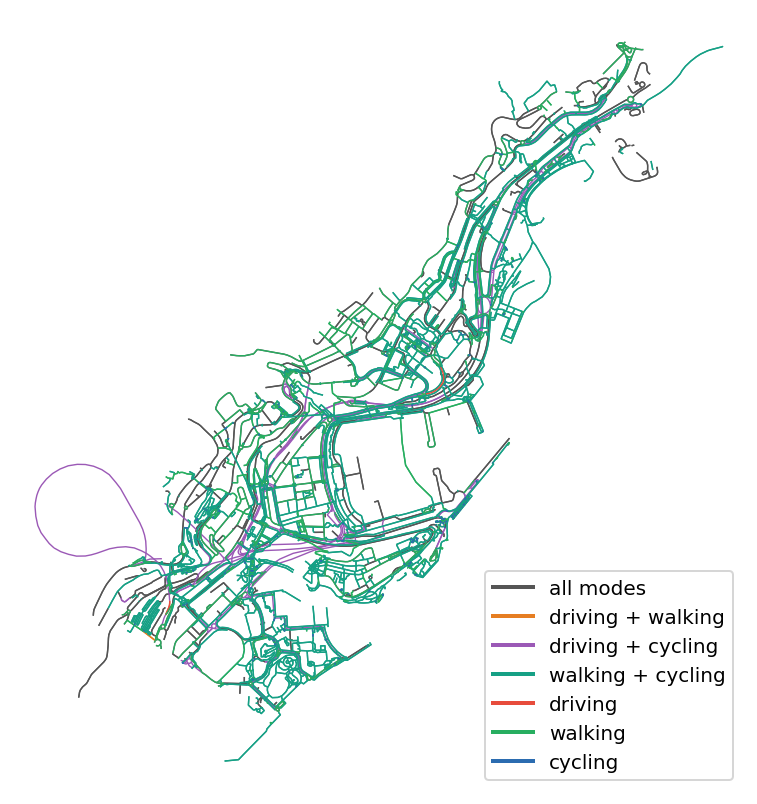

In [4]:
net.plot()         # the matplotlib picture of all modes

These are also the colors of the "Modes" option of the dashboard, so the picture and the dashboard agree.

| Modes that can use the road | Name in the legend | Color |
|---|---|---|
| driving, walking and cycling | all modes | dark gray `#555555` |
| driving and walking | driving + walking | orange `#e67e22` |
| driving and cycling | driving + cycling | purple `#9b59b6` |
| walking and cycling | walking + cycling | green-blue `#16a085` |
| driving only | driving | red `#e74c3c` |
| walking only | walking | green `#27ae60` |
| cycling only | cycling | blue `#2b6cb0` |

The cell below counts the roads of each set. `pd.crosstab` makes a table with one row for each `edge_id` and one
column for each mode: 1 when the mode has the road, 0 when it does not. `value_counts` then counts the rows of each
set.

In [5]:
import pandas as pd

edges = net.edges()                                       # all modes, with a "mode" column
in_mode = pd.crosstab(edges["edge_id"], edges["mode"])    # one row for each road, one column for each mode
in_mode[["driving", "walking", "cycling"]].value_counts() # the number of roads of each set of modes

driving  walking  cycling
0        1        1          7751
1        1        1          2196
0        1        0          1986
         0        1           725
1        0        1           633
                  0             6
         1        0             5
Name: count, dtype: int64

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> Each row is one set of modes: 1 means that the mode has the road. Of the 13302 roads, 7751 are for walking and cycling only (0, 1, 1: the footways and the paths), and 2196 are for all modes (1, 1, 1). Only 6 roads are for driving only, because most motor roads of Monaco have a sidewalk or let bicycles in. 5 roads are for driving and walking. In the picture, most roads are green-blue, the streets of all modes are dark gray, and the tunnel loop in the west is purple (driving and cycling).

## How the notebook shows a map: `show`

A live map is a web page of approximately 6 MB. A saved notebook with many live maps is large, and GitHub does not
show it. So the outputs on this page come from a run with `DUCKOSM_MAP_SHOW=picture`: each map is a picture of the
live map. When you run the cells yourself, you get the live map.

The argument `show` chooses how the notebook shows a map. Without it, duckOSM uses the environment variable
`DUCKOSM_MAP_SHOW`, and without that, `"live"`.

| `show` | What you get when you run the cell | Size (Monaco) |
|---|---|---|
| `"live"` | the live roadstyle map in the output of the cell | about 6 MB in the notebook |
| `"link"` | the live map saved as an HTML file, and a link "Open the live map" in the output | a link. The file is about 6 MB |
| `"picture"` | a PNG of the live map, taken in a hidden Chromium browser | about 150 KB |
| `"plot"` | `net.plot()`: the matplotlib picture, without roadstyle | a small PNG |

`"link"` and `"picture"` write their file to `path`. The default is `maps/<file>-<n>.html` or
`maps/<file>-<n>.png`, where `<n>` counts the maps of the session. `"picture"` needs Playwright:
`pip install playwright`, then `playwright install chromium`. To give one default for all maps of a session, set
the variable in Python: `os.environ["DUCKOSM_MAP_SHOW"] = "picture"`.

In [6]:
net.map(show="link", path="maps/monaco.html")        # the live map as a file, and a link to it

MapLink('maps/monaco.html')

The link opens the saved file in a new browser tab. On the manual page the file is not there, so the link works
only in your own notebook.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-tip.svg" width="18" height="18" alt=""> **Tip**
>
> Use `"link"` in a notebook that you share: the notebook stays small, and the HTML file opens in each browser without a server. Use `"picture"` when you want the look of the live map in a saved notebook.

## The map of one mode

`net.map("driving")`, or `net.driving.map()`, draws one mode. The live map then has only the roads of that mode. The
static picture gives one color to each road class (`highway`). Here `show="plot"` gives the static picture.

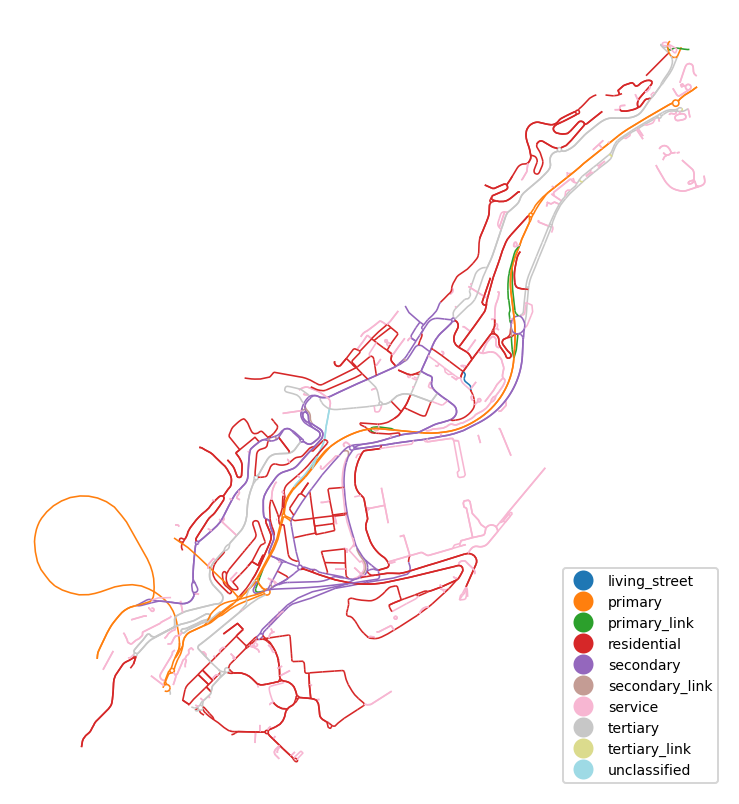

In [7]:
net.map("driving", show="plot")     # the driving network, one color for each road class

The legend lists the road classes of the driving network, from `living_street` to `unclassified`. The tunnel
loop in the west is a `primary` road.

## The base map: `layers`

`layers` chooses the base map under the roads.

| `layers` | The live map | The static picture |
|---|---|---|
| not given | all layers of the file | the roads only |
| `True` | all layers | the five layers below |
| `False` | the roads only | the roads only |
| a list of names | those layers | those layers, of the five |

The static picture draws five layers: `ocean`, `landcover`, `water`, `waterways` and `buildings`. Another name gives
an error that lists the five. The live map has all the layers of roadstyle, for example `paved`, `railways`,
`parking`, `traffic_signals`, `crossings` and `train_stations`. Its layers button turns each one on and off.

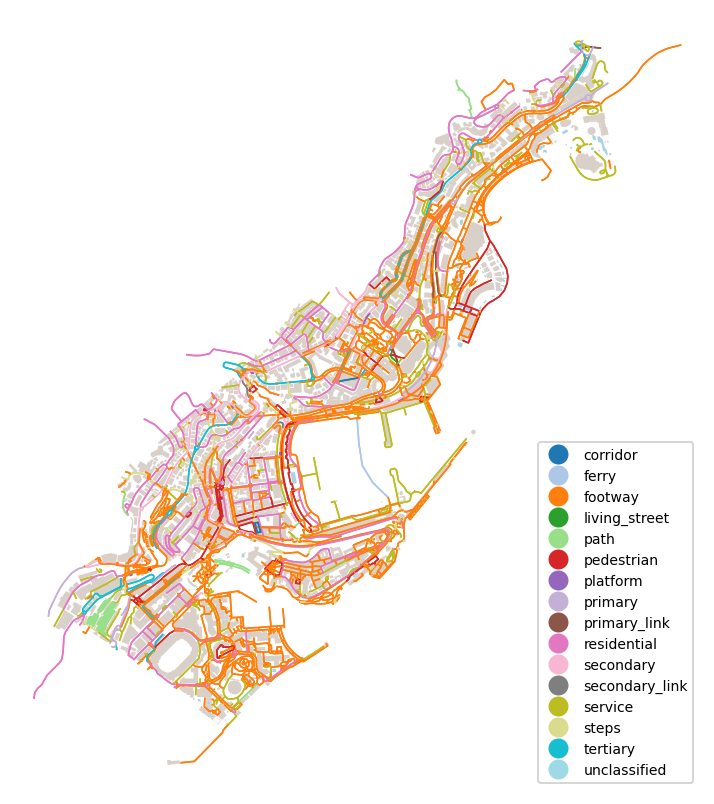

In [8]:
net.plot("walking", layers=["water", "buildings"])    # the walking network over two layers of the base map

The buildings are light gray-brown under the walking roads, and the small water areas are light blue. The view stops
at a small margin around the roads, so the sea does not fill the picture.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-warning.svg" width="18" height="18" alt=""> **Warning**
>
> With `color_by` or `routes`, the live map has the default base map of roadstyle, and `layers` has no effect. This limit of roadstyle can change in a later version.

## The themes: `theme`

`theme` chooses the colors of the live map: `"liberty"` (the default), `"osm"`, `"google"`, `"grey"` or
`"roadstyle"`. The static picture has one look, so `theme` changes only the live map.

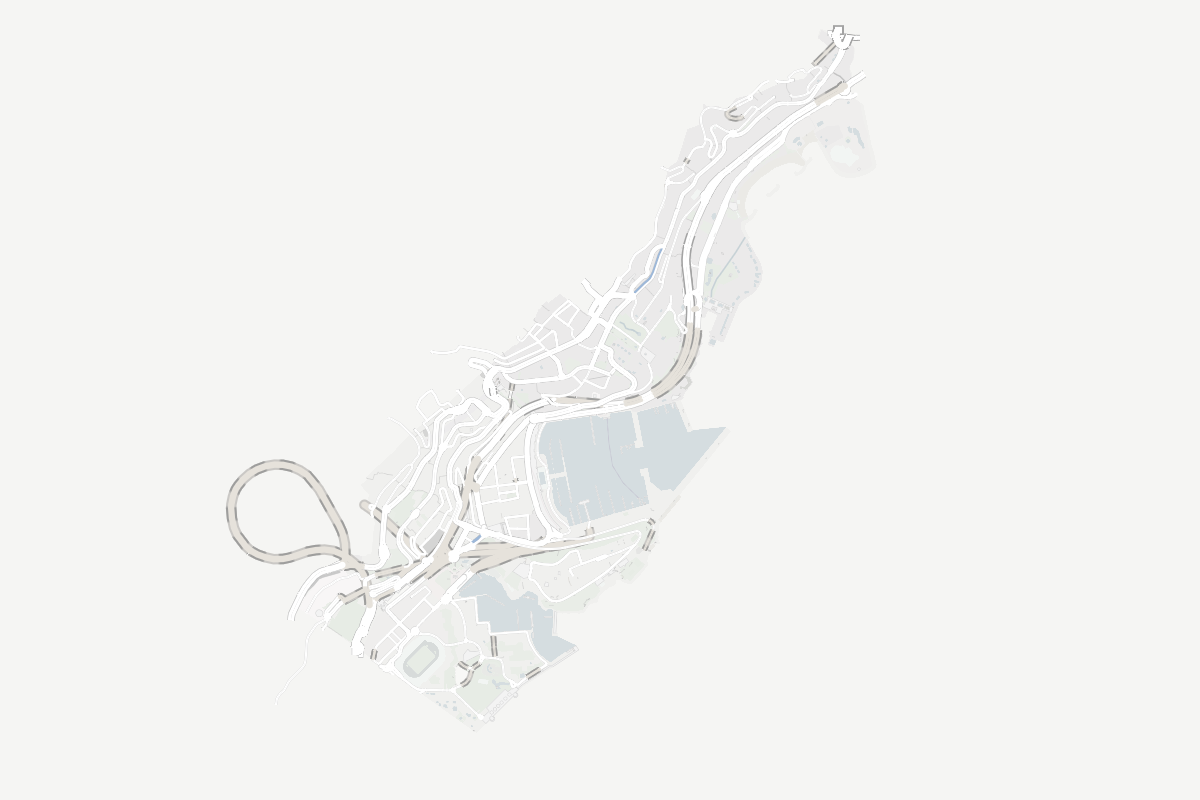

In [9]:
net.map(theme="grey")      # the live map with the gray theme

In the gray theme, the roads are white and light gray, and the harbors are gray-blue. The tunnels stay dashed. Use
this theme as a quiet background when you want your own colors to stand out.

## Color the roads by a column: `color_by`

`color_by` gives each road a color from a column. A number column gets a color ramp: `cmap` chooses it (a matplotlib
name, for example `"viridis"` or `"magma_r"`). A text column has classes: give `colors`, a dict of value and color.
Roads without a value are gray.

| Option | Takes |
|---|---|
| `color_by` | the name of a column of the edges, or your own data: a pandas Series with `edge_id` as its index, or a DataFrame with `edge_id` and one value column (chapter 4) |
| `cmap` | the color ramp of a number column |
| `colors` | `{value: color}` for a text column |

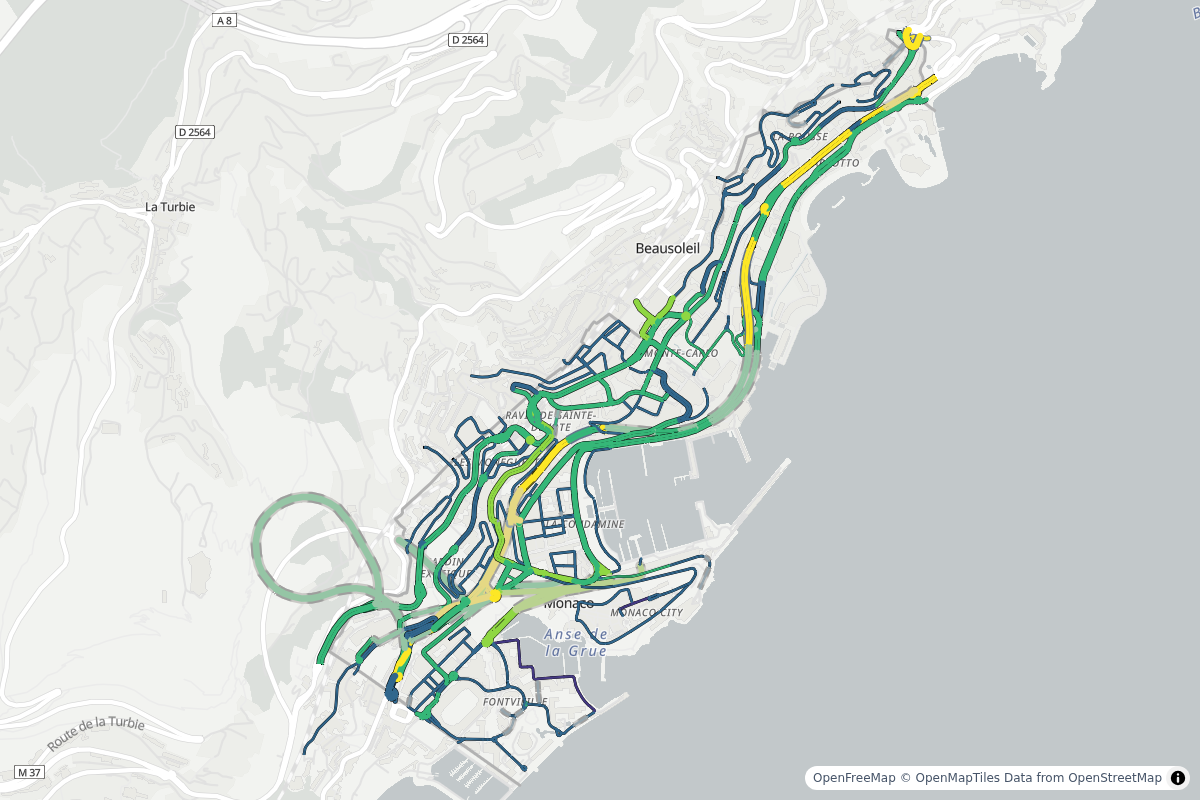

In [10]:
net.map("driving", color_by="maxspeed_kmh", cmap="viridis")      # the speed limit of each road

The colors go from dark blue (10 km/h) to yellow (70 km/h). Most driving edges have 20 or 30 km/h (dark blue
and blue): 1809 of the 2840. The roads with 50 km/h are green. The 142 edges with 70 km/h (yellow) are on the main
roads along the coast.

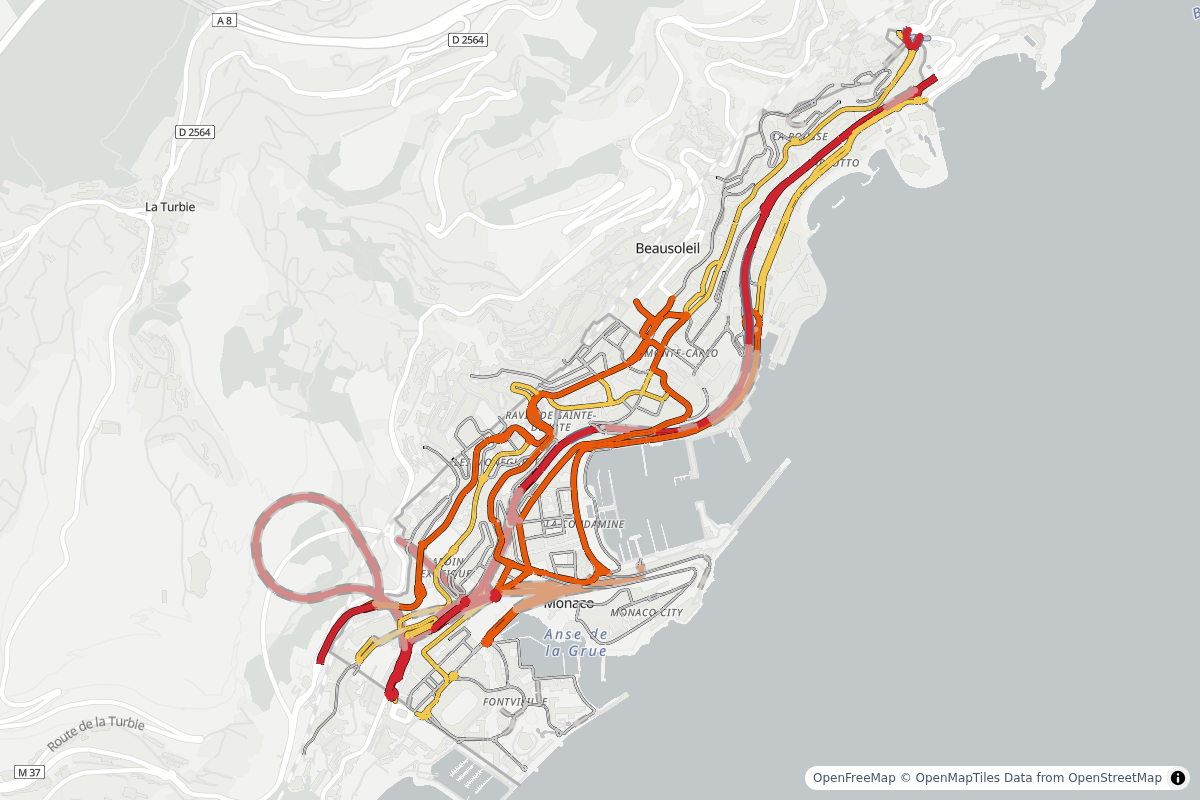

In [11]:
net.map("driving", color_by="highway",
        colors={"primary": "#d1242f", "secondary": "#e8590c", "tertiary": "#f2c94c"})   # three classes, the rest gray

The primary roads are red, the secondary roads orange and the tertiary roads yellow. The other classes are thin
gray lines.

## Highlight some edges: `highlight`

`highlight` takes a list of `edge_id` values. These edges are orange, and all other edges are gray. Use it to show
the result of a query. Here the query gives the edges of one street.

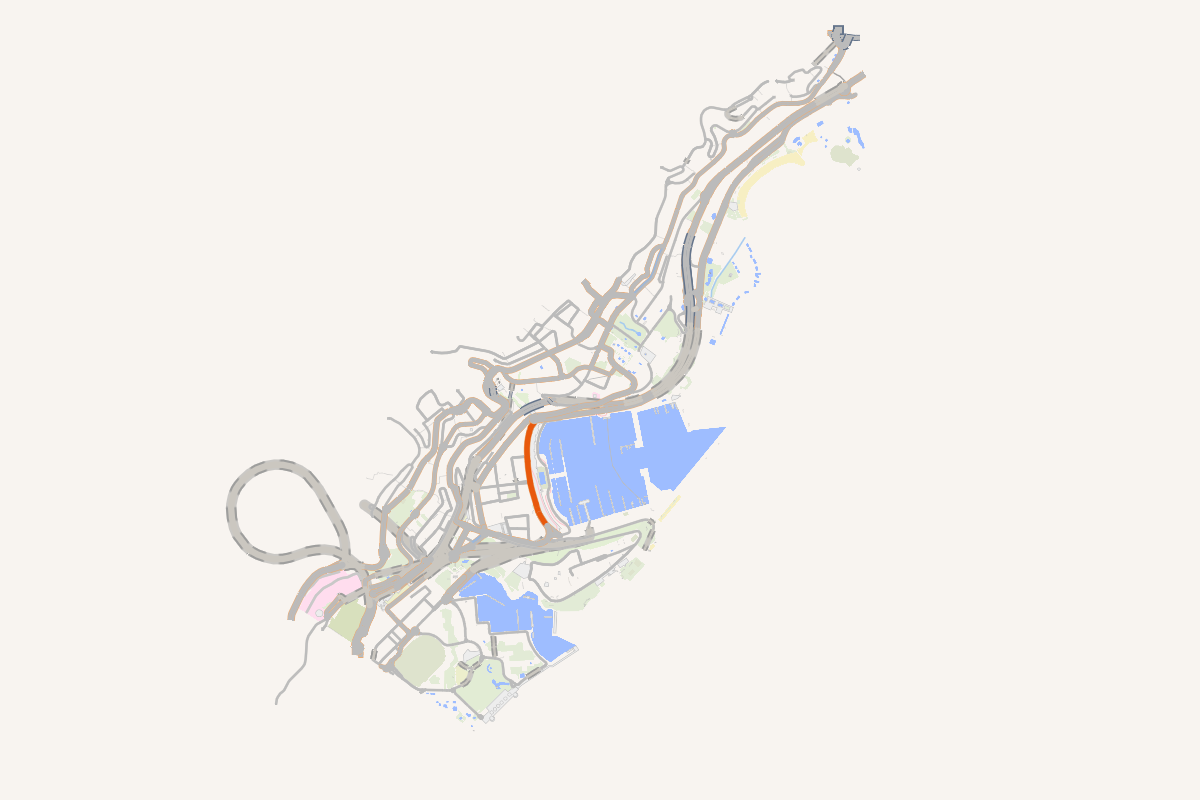

In [12]:
albert = net.sql("SELECT edge_id FROM driving.edges WHERE name = 'Boulevard Albert 1er'").edge_id   # one street
net.map("driving", highlight=albert)                                                              # in orange

The Boulevard Albert 1er is the orange line along the west side of the harbor.

## Draw a route: `routes`

`routes` draws one route, a list of routes or a dict of label and route over the roads, each in its own color.
Chapter 7 tells how to compute a route. Here the route goes by car from the south-west of Monaco to the north-east.

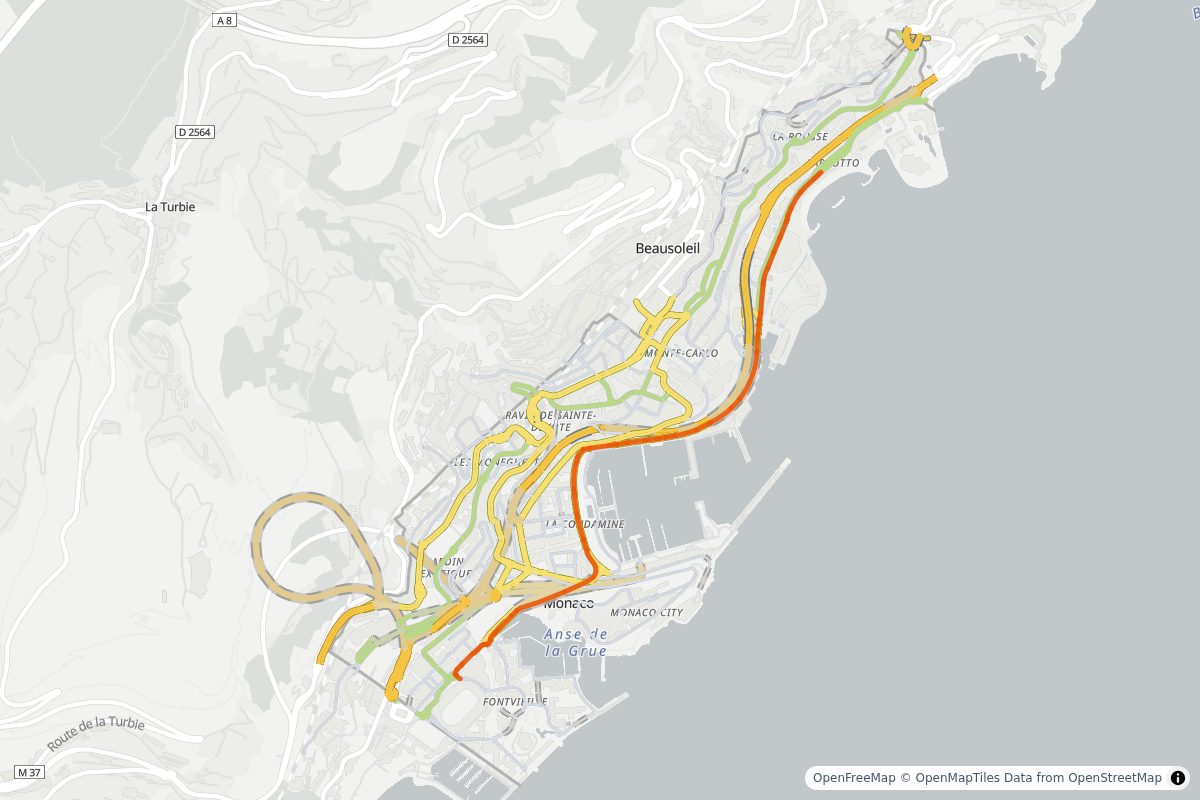

In [13]:
route = net.driving.route_points((7.4155, 43.7285), (7.4335, 43.7468))     # (lon, lat) to (lon, lat)
net.map("driving", routes={"by car": route})                                # the route over the roads

The route is the dark orange line, with the label "by car" in the legend of the live map. In the live map,
click the line to see its time and its length.

## The dashboard: `net.dashboard()`

`net.dashboard()` is roadstyle's dashboard page: the live map with a panel next to it. Click a road, and the panel
shows its card: all its columns. The color menu of the panel colors the roads by road class or by **Modes** (the
colors of the table in "The static picture"). `mode`, `show`, `path` and `layers` work as in `net.map()`.

A picture cannot show the card of a road, because you must click the road first. So the cell gives a link to the
dashboard. Chapter 4 shows a picture of the dashboard with a road card.

In [14]:
net.dashboard(show="link", path="maps/dashboard.html")     # the dashboard of all modes, as a file and a link

MapLink('maps/dashboard.html')

## Save a map as a file: `net.save_map()`

`net.save_map(path)` writes the live map as one offline HTML file and gives its path. It takes the options of
`net.map()`: `mode`, `theme`, `color_by`, `highlight`, `routes` and `layers`. With `dashboard=True`, it writes the
dashboard. Send the file to a person who has no Python: it opens in each browser, without a server and without the
internet.

In [15]:
print(net.save_map("out/monaco.html"))                                            # the map of all modes
print(net.save_map("out/driving-speed.html", "driving", color_by="maxspeed_kmh"))  # one mode, colored

out/monaco.html


out/driving-speed.html


The two files are in the folder `out`.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-tip.svg" width="18" height="18" alt=""> **Tip**
>
> `net.save_map()` gives the same file as `net.map(show="link", path=...)`, but it shows no link. Use it in a script.

## Web maps with folium and lonboard

The edges of duckOSM are a GeoDataFrame, so the web-map tools of Python draw them directly:

| Tool | What it is good for | How it gets the edges |
|---|---|---|
| [folium](https://python-visualization.github.io/folium/) | a quick interactive map on a light base map, with a pop-up for each road | `edges.explore()` of GeoPandas uses folium |
| [lonboard](https://developmentseed.org/lonboard/) | large data: it draws on the graphics card of the computer, so many thousands of lines stay fast | `PathLayer.from_geopandas(edges)` |

Both maps use the same simple light gray base map, Esri World Gray Canvas, so the colored roads stand out. Both maps have a full-screen button, show the columns of a road when the mouse is over it, and save as a web page
that any browser opens.

### folium

`explore` puts the columns of the GeoDataFrame into a tooltip (when the mouse is over a road) and, with `popup=True`,
into a pop-up (when you click a road). The cell keeps only five columns, so the map stays small. `Fullscreen` adds the
full-screen button, and `save` writes the map as a web page.

In [16]:
import folium.plugins

edges = net.driving.edges()[["edge_id", "name", "highway", "maxspeed_kmh", "geometry"]]    # five columns
fmap = edges.explore(column="maxspeed_kmh", cmap="viridis", tiles="Esri.WorldGrayCanvas",
                     style_kwds={"weight": 3}, legend_kwds={"caption": "speed limit, km/h"},
                     popup=True)                                                # color by the speed limit
folium.plugins.Fullscreen().add_to(fmap)                                        # the full-screen button
fmap.save("out/folium_driving.html")                                           # the map as a web page
fmap

The roads have the color of their speed limit. Zoom in, and move the mouse over a road to see its name, its
class and its speed limit. Click it to keep them in a pop-up. The file `out/folium_driving.html` is the same map.

### lonboard

This map draws all 11,938 walking edges, colored by their length. lonboard gives each line its color as an array, so
the cell makes the colors with a matplotlib color ramp. lonboard takes its base map as a MapLibre style at a web
address: the book has a small style file for the Esri map. The cell saves the map as a web page with `to_html` and shows the page
in a frame. In Colab, show the map with `lmap` alone in a cell.

In [17]:
import matplotlib
from IPython.display import IFrame
from lonboard import Map, PathLayer
from lonboard.basemap import MaplibreBasemap
from lonboard.colormap import apply_continuous_cmap

walk = net.walking.edges()[["edge_id", "name", "highway", "length_m", "geometry"]]    # all the walking edges
walk["length_m"] = walk.length_m.round(1)                                      # 0.1 m is enough in the tooltip
share = (walk.length_m.clip(0, 100) / 100).to_numpy()                           # 0 to 1: up to 100 m long
layer = PathLayer.from_geopandas(walk, get_width=2, width_units="pixels",
                                 get_color=apply_continuous_cmap(share, matplotlib.colormaps["viridis"]))
esri = "https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/esri-light-gray.json"    # the base map
lmap = Map(layer, basemap=MaplibreBasemap(style=esri), show_tooltip=True)      # the lonboard map, with a tooltip
lmap.to_html("lonboard_walking.html")                                           # saved as a web page
IFrame("lonboard_walking.html", width="100%", height=520, extras=["allowfullscreen"])    # the page in a frame

Move the mouse over a road to see its `edge_id`, name, class and length, and click it to keep them in a side
panel. The square button at the bottom right draws a box to select the roads in it. The box goes back to Python as
`lmap.selected_bounds`, so it is useful only in a running notebook, not in this book.

The short edges are dark purple and the edges of 100 m or more are yellow. Most walking edges are short: the
footways and the steps of Monaco are cut at each junction.

## A picture for a paper: `net.plot(ax=...)`

`net.plot()` takes the options of `net.map()` (`color_by`, `cmap`, `colors`, `highlight`, `routes`) and `layers`
(default `False`: the roads only). With `ax`, it draws on your own matplotlib axes. Then you can add your own layers
on the same axes and save the figure as PNG or PDF.

The cell below draws the driving roads in gray with the Boulevard Albert 1er in orange (`highlight`). Then it adds
two layers of its own: the outline of the city (`net.boundary.boundary` gives the lines around the polygon) and a
point at the casino square. The legend has a handle for each of the three.

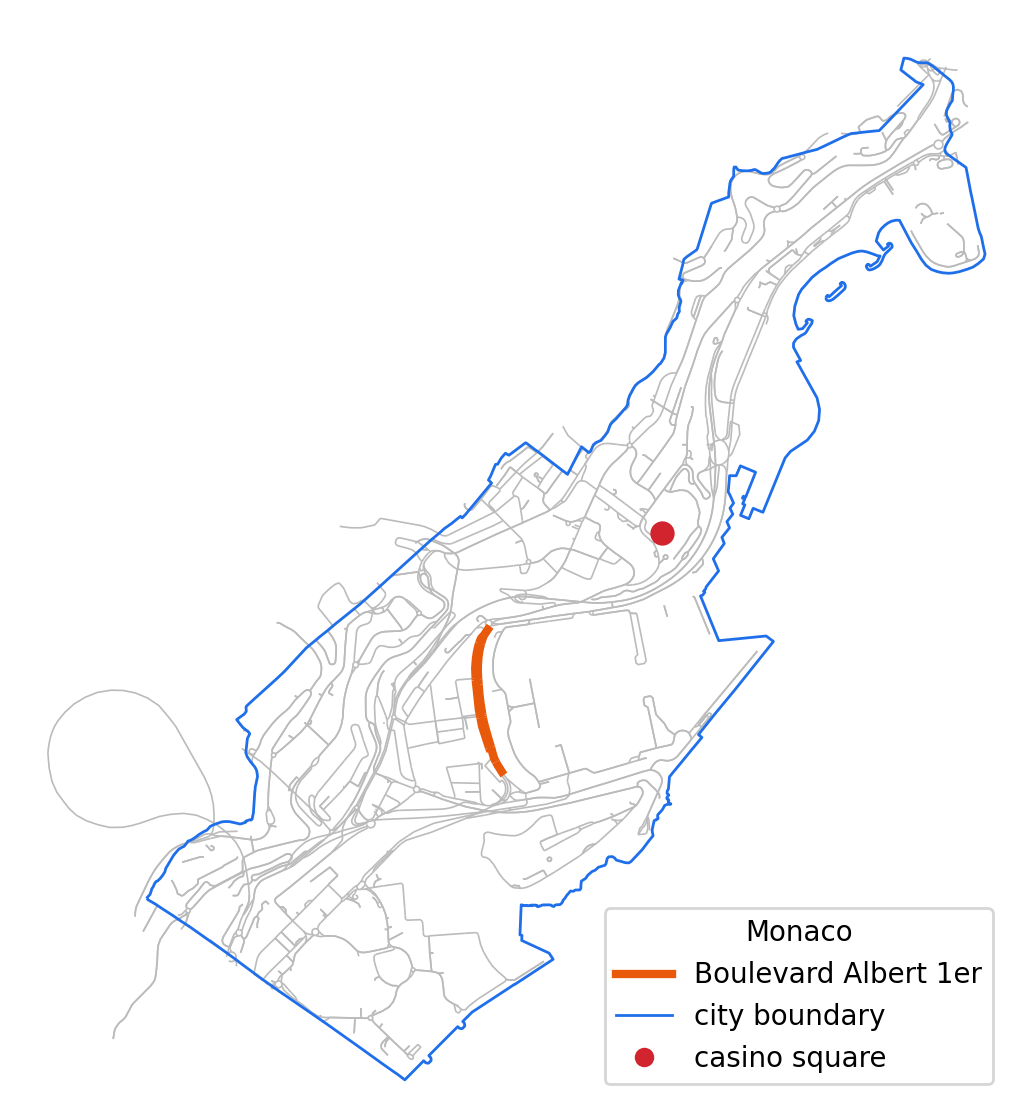

In [18]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(7, 7))
net.plot("driving", highlight=albert, ax=ax)                           # gray roads, the boulevard in orange
net.boundary.boundary.plot(ax=ax, color="#1f6feb", linewidth=1)       # your layer: the outline of the city
ax.scatter([7.4280], [43.7393], color="#d1242f", s=60, zorder=3)      # your layer: the casino square
ax.legend(title="Monaco", loc="lower right", handles=[
    Line2D([], [], color="#e8590c", linewidth=3, label="Boulevard Albert 1er"),
    Line2D([], [], color="#1f6feb", linewidth=1, label="city boundary"),
    Line2D([], [], color="#d1242f", marker="o", linestyle="", label="casino square")])
fig.savefig("out/monaco-paper.png", dpi=150, bbox_inches="tight")    # a PNG for a paper (".pdf" gives a PDF)
plt.show()

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The gray driving roads, the orange boulevard at the harbor, the blue outline of the city and the red point of the casino square, with the legend "Monaco". The file `out/monaco-paper.png` has the same figure at 150 dots per inch.

## Try it yourself

**1.** Draw the walking network, colored by `length_m`, with the color ramp `"plasma"`.

<details><summary>Show the answer</summary>

```python
net.map("walking", color_by="length_m", cmap="plasma")
```
</details>

**2.** Highlight the steps of the walking network.

<details><summary>Show the answer</summary>

```python
steps = net.walking.edges(where="highway = 'steps'").edge_id
net.map("walking", highlight=steps)
```
</details>

**3.** Save the dashboard of the cycling network as `out/cycling.html`, with the theme `"osm"`.

<details><summary>Show the answer</summary>

```python
net.save_map("out/cycling.html", "cycling", dashboard=True, theme="osm")
```
</details>

**4.** Make a picture of the driving network over the buildings and the water, and save it as a PDF.

<details><summary>Show the answer</summary>

```python
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 8))
net.plot("driving", layers=["water", "buildings"], ax=ax)
fig.savefig("out/driving.pdf")
```
</details>

## Words in this chapter

| Word | Meaning |
|---|---|
| live map | the roadstyle map in the browser: you can zoom and click |
| static picture | the matplotlib picture of `net.plot()`: a PNG or a PDF |
| roadstyle | the library that draws the live map and the dashboard |
| base map | the layers under the roads: buildings, water, land, from the `features` schema |
| theme | the colors of the live map: liberty, osm, google, grey, roadstyle |
| color ramp | a range of colors for a number column (`cmap`) |
| dashboard | the live map with a panel: the card of the road that you click, and the color menu |
| `DUCKOSM_MAP_SHOW` | the environment variable that gives the default of `show` |

## Summary

| Call | Does |
|---|---|
| `net.map(mode=None, show=, path=, layers=, theme=)` | the live map. `show` chooses live, link, picture or plot |
| `net.map(..., color_by=, cmap=, colors=)` | the roads colored by a column or by your own data |
| `net.map(..., highlight=)` | some edges in orange, the rest gray |
| `net.map(..., routes=)` | routes over the roads |
| `net.dashboard(mode=None, show=, path=, layers=)` | the live map with the panel: the road card and the color menu |
| `net.save_map(path, mode=None, dashboard=False, **options)` | the live map or the dashboard as one HTML file |
| `net.plot(mode=None, layers=False, ax=None, ...)` | the static matplotlib picture |
| `net.walking.map()`, `.plot()`, `.dashboard()`, `.save_map()` | the same calls for one mode |

The reference: [Python SDK, Maps](../reference/python.md#maps). **Next:** [4. Join your data by edge_id](04_join_by_edge_id.md), your own data on the edges, and on the map.